In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import pandas as pd

## Extracción de Datos

In [2]:
# Jupyter ejecuta el notebook desde su propia carpeta ("Calibraciones 10-11-2026"),
# así que las rutas relativas funcionan en cualquier clon del repositorio.
BASE = Path.cwd()

RUTA_REF = BASE / "17019_segundos_2026-11-10T17-32.dat"
RUTAS_DOMOS = {
    "Domo 1": [BASE / "Domo_1" / "20261110.csv"],
    "Domo 2": [BASE / "Domo_2" / "20261110.csv"],
    # El Domo 3 no tiene archivo del 10-11: en su SD solo hay archivos de días
    # anteriores (copias de las calibraciones del 03-11 y 04-11) y un 20000101.csv
    # de ~1 h con presión de 683 hPa, que no corresponde a este experimento.
    # "Domo 3": [BASE / "Domo_3" / "20261110.csv"],
    # El RTC del Domo 4 volvió a perder la hora (arrancó en 2000-01-01):
    # el experimento quedó repartido en estos 2 archivos.
    "Domo 4": [
        BASE / "Domo_4" / "20000101.csv",
        BASE / "Domo_4" / "20000102.csv",
    ],
}

# Avisa con un mensaje claro si falta algún archivo, antes de intentar leer.
faltantes = [r for r in [RUTA_REF, *sum(RUTAS_DOMOS.values(), [])] if not r.exists()]
if faltantes:
    raise FileNotFoundError(
        "No se encontraron estos archivos:\n  "
        + "\n  ".join(str(r.relative_to(BASE)) for r in faltantes)
    )

def leer_referencia(ruta):
    """Archivo TOA5 del Campbell CR300.
    Encabezado: fila 0 = metadatos, 1 = nombres, 2 = unidades, 3 = tipo de dato."""
    return pd.read_csv(
        ruta,
        skiprows=[0, 2, 3],
        na_values=["NAN"],
        parse_dates=["TIMESTAMP"],
        index_col="TIMESTAMP",
    )

def leer_domo(rutas):
    """Lee uno o varios CSV de un mismo domo y los une en una sola serie de tiempo."""
    partes = []
    for ruta in rutas:
        df = pd.read_csv(ruta, parse_dates=["Timestamp"])
        df["archivo"] = ruta.name  # de qué archivo viene cada fila (útil en el Domo 4)
        partes.append(df)
    df = pd.concat(partes, ignore_index=True)

    # Quita la fila que escribe el firmware al encender (todos los sensores en NaN).
    sensores = df.columns.difference(["Timestamp", "Timeon", "archivo"])
    df = df.dropna(subset=sensores, how="all")

    return df.set_index("Timestamp")

# Un DataFrame independiente por fuente, todos en un mismo diccionario.
datos = {"Referencia": leer_referencia(RUTA_REF)}
for nombre, rutas in RUTAS_DOMOS.items():
    datos[nombre] = leer_domo(rutas)

# Accesos directos (son los mismos objetos que hay en `datos`).
df_ref = datos["Referencia"]
df_d1 = datos["Domo 1"]
df_d2 = datos["Domo 2"]
df_d4 = datos["Domo 4"]

# Resumen
for nombre, df in datos.items():
    print(f"{nombre:<10} {len(df):>6} filas  {df.index.min()} -> {df.index.max()}")


Referencia   3144 filas  2026-11-10 08:49:00 -> 2026-11-10 17:32:50
Domo 1      32389 filas  2026-11-10 08:43:08 -> 2026-11-10 17:43:13
Domo 2      32256 filas  2026-11-10 08:43:44 -> 2026-11-10 17:41:51
Domo 4      31746 filas  2000-01-01 21:41:04 -> 2000-01-02 06:30:35


## Corrección de Hora de la Estación Domo 4

In [3]:
# ---------------------------------------------------------------------------
# Configuración
# ---------------------------------------------------------------------------
FECHA_EXPERIMENTO = pd.Timestamp("2026-11-10")
BASES = ["Domo 1"]  # domos con la hora correcta (el Domo 3 no tiene datos este día)

# Qué parte de cada DataFrame se cuadra y con qué columna se compara.
# "archivo": None = todo el DataFrame; si no, solo las filas de ese archivo.
A_CUADRAR = {
    "Referencia": {"columna": "RH", "archivo": None, "paso": "10s"},  # registra cada 10 s
    "Domo 2": {"columna": "DHT_Hum", "archivo": None, "paso": "1s"},
    # El RTC del Domo 4 perdió la hora (arrancó en 2000-01-01): se cuadra completo.
    "Domo 4": {"columna": "DHT_Hum", "archivo": None, "paso": "1s"},
}
COLUMNA_BASE = "DHT_Hum"
RANGO_BUSQUEDA = pd.Timedelta(minutes=40)  # ± alrededor de la estimación inicial


# ---------------------------------------------------------------------------
# Funciones
# ---------------------------------------------------------------------------
def regularizar(serie, paso):
    """Promedia en una grilla regular y rellena huecos cortos."""
    serie = serie[~serie.index.duplicated()].sort_index()
    return serie.resample(paso).mean().interpolate(limit=6, limit_area="inside")


def buscar_desfase(serie, base, centro, rango, paso):
    """Corrimiento en [centro - rango, centro + rango] que maximiza la correlación."""
    s = regularizar(serie, paso)
    b = regularizar(base, paso)
    paso = pd.Timedelta(paso)
    centro = centro.round(paso)  # el centro debe caer en la grilla
    n = int(rango / paso)
    candidatos = [centro + k * paso for k in range(-n, n + 1)]
    r = [s.set_axis(s.index + c).reindex(b.index).corr(b) for c in candidatos]
    if np.all(np.isnan(r)):
        raise ValueError(
            f"Ningún corrimiento entre {centro - rango} y {centro + rango} hace que "
            f"'{serie.name}' se superponga con la base. Revisa la estimación inicial "
            f"o amplía RANGO_BUSQUEDA."
        )
    i = int(np.nanargmax(r))
    return candidatos[i], r[i]


def estimar_desfase(serie, base, paso):
    """Búsqueda gruesa (10 s, ±40 min) y fina (paso, ±20 s)."""
    # Estimación inicial: todos los equipos se encendieron casi al mismo tiempo,
    # así que se alinean los inicios de registro. Esto sirve aunque el RTC haya
    # perdido la fecha Y la hora (como el Domo 4, que arrancó a las 21:41 del 2000-01-01).
    centro = base.index.min() - serie.index.min()
    desfase, r = buscar_desfase(serie, base, centro, RANGO_BUSQUEDA, "10s")
    if pd.Timedelta(paso) < pd.Timedelta("10s"):
        desfase, r = buscar_desfase(serie, base, desfase, pd.Timedelta("20s"), paso)
    return desfase, r


def formato(td):
    signo = "-" if td < pd.Timedelta(0) else "+"
    td = abs(td)
    seg = int(td.total_seconds()) % 86400
    dias = f"{td.days} d " if td.days else ""
    return f"{signo}{dias}{seg // 3600:02d}:{seg // 60 % 60:02d}:{seg % 60:02d}"


# ---------------------------------------------------------------------------
# Estimación
# ---------------------------------------------------------------------------
resultados = []
for nombre, cfg in A_CUADRAR.items():
    df = datos[nombre]
    if cfg["archivo"] is not None:
        df = df[df["archivo"] == cfg["archivo"]]
    serie = df[cfg["columna"]]
    if nombre == "Referencia":
        serie = serie.loc[FECHA_EXPERIMENTO.strftime("%Y-%m-%d")]

    for base in BASES:
        desfase, r = estimar_desfase(serie, datos[base][COLUMNA_BASE], cfg["paso"])
        resultados.append({"estacion": nombre, "base": base, "desfase": desfase, "r": r})

resultados = pd.DataFrame(resultados)

# Desfase final: promedio de lo obtenido contra las bases, redondeado a 1 s.
DESFASES = resultados.groupby("estacion", sort=False)["desfase"].mean().dt.round("1s").to_dict()

print(resultados.assign(desfase=resultados["desfase"].map(formato), r=resultados["r"].round(4))
      .to_string(index=False))
print("\nDesfase aplicado (se suma a la hora registrada):")
for nombre, d in DESFASES.items():
    print(f"  {nombre:<10} {formato(d)}")


# ---------------------------------------------------------------------------
# Aplicación: nuevo diccionario `datos_sync`; `datos` queda intacto.
# La hora original se conserva en la columna "Hora_RTC".
# ---------------------------------------------------------------------------
datos_sync = {}
for nombre, df in datos.items():
    df = df.copy()
    df.insert(0, "Hora_RTC", df.index)
    if nombre in DESFASES:
        archivo = A_CUADRAR[nombre]["archivo"]
        filas = np.ones(len(df), bool) if archivo is None else (df["archivo"] == archivo).to_numpy()
        nuevo = df.index.to_series()
        nuevo[filas] = nuevo[filas] + DESFASES[nombre]
        df.index = pd.DatetimeIndex(nuevo, name=df.index.name)
    datos_sync[nombre] = df

df_ref, df_d1, df_d2, df_d4 = (datos_sync[k] for k in ["Referencia", "Domo 1", "Domo 2", "Domo 4"])

for nombre, df in datos_sync.items():
    print(f"{nombre:<10} {df.index.min()} -> {df.index.max()}")


  estacion   base          desfase      r
Referencia Domo 1        +00:00:00 0.9885
    Domo 2 Domo 1        -00:00:01 0.9996
    Domo 4 Domo 1 +9809 d 11:06:23 0.9998

Desfase aplicado (se suma a la hora registrada):
  Referencia +00:00:00
  Domo 2     -00:00:01
  Domo 4     +9809 d 11:06:23
Referencia 2026-11-10 08:49:00 -> 2026-11-10 17:32:50
Domo 1     2026-11-10 08:43:08 -> 2026-11-10 17:43:13
Domo 2     2026-11-10 08:43:43 -> 2026-11-10 17:41:50
Domo 4     2026-11-10 08:47:27 -> 2026-11-10 17:36:58


## Revisión de comportamiento de Datos

In [4]:
# ---------------------------------------------------------------------------
# Datos del día del experimento (hora ya cuadrada en `datos_sync`)
# ---------------------------------------------------------------------------
FECHA = "2026-11-10"
ESTACIONES = ["Domo 1", "Domo 2", "Domo 4"]

# Para el Domo 4 esto deja solo las filas del experimento: sus otros archivos
# (marzo-octubre) quedan fuera.
exp = {nombre: df.loc[FECHA].sort_index() for nombre, df in datos_sync.items()}

# El SHT40 entrega valores en los extremos de su escala cuando falla la lectura
# (-45 / -37.7 / 130 °C, 0 / 100 %). Se marcan como NaN para no graficarlos.
for nombre in ESTACIONES:
    df = exp[nombre]
    invalido = ~(df["SHT_Temp"].between(-40, 125, inclusive="neither")
                 & df["SHT_Hum"].between(0, 100, inclusive="neither"))
    exp[nombre] = df.assign(
        SHT_Temp=df["SHT_Temp"].mask(invalido),
        SHT_Hum=df["SHT_Hum"].mask(invalido),
    )

COLORES = {"Domo 1": "#2a78d6", "Domo 2": "#eb6834", "Domo 3": "#1baf7a", "Domo 4": "#eda100"}
COLOR_REF = "#3d3d3a"
COLOR_GRILLA = "#e4e3df"


def graficar_vs_referencia(exp, col_domo, col_ref, etiqueta, titulo, margen, sensor="SHT40"):
    """Un panel por estación: SHT40 (color) vs. referencia (línea discontinua).

    La escala Y es la misma en todos los paneles y se ajusta al rango de la
    referencia ± `margen`; los puntos que quedan fuera se cuentan en el panel.
    """
    ref = exp["Referencia"][col_ref]
    y_min, y_max = ref.min() - margen, ref.max() + margen

    fig, ejes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True,
                             layout="constrained")
    for ax, nombre in zip(ejes.flat, ESTACIONES):
        serie = exp[nombre][col_domo]
        ax.plot(serie.index, serie, lw=1.2, color=COLORES[nombre], label=f"{nombre} ({sensor})")
        ax.plot(ref.index, ref, lw=1.5, ls="--", color=COLOR_REF, label="Referencia")

        fuera = int(((serie < y_min) | (serie > y_max)).sum())
        validos = int(serie.notna().sum())
        nota = f"{validos} lecturas válidas"
        if fuera:
            nota += f"\n{fuera} fuera de escala"
        ax.text(0.99, 0.03, nota, transform=ax.transAxes, ha="right", va="bottom",
                fontsize=8, color="#5f5e5a")

        ax.set_title(nombre, loc="left", fontsize=11)
        ax.legend(loc="upper left", frameon=False, fontsize=8)
        ax.grid(True, color=COLOR_GRILLA, lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)

    ejes[0, 0].set_ylim(y_min, y_max)
    for ax in ejes[:, 0]:
        ax.set_ylabel(etiqueta)
    for ax in ejes[-1]:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.set_xlabel(f"Hora ({FECHA})")
    fig.suptitle(titulo)
    return fig, ejes

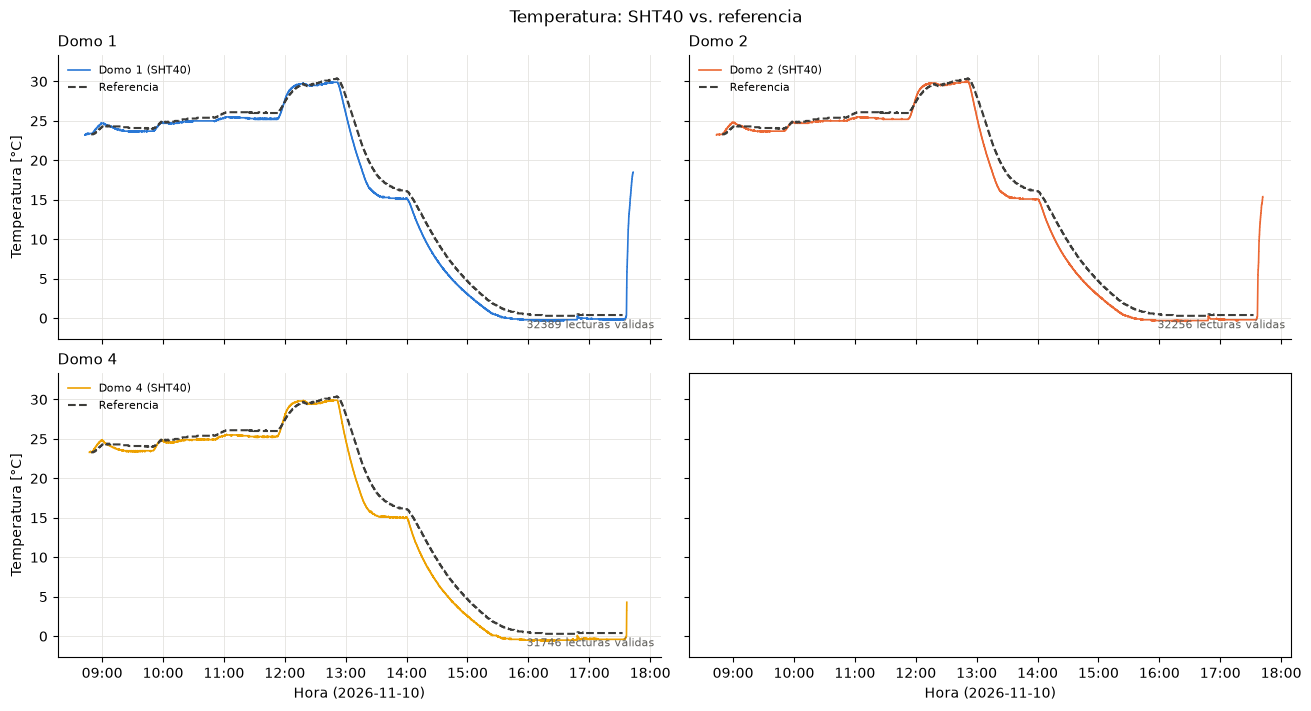

In [5]:
fig_t, _ = graficar_vs_referencia(exp, "SHT_Temp", "AirT_C", "Temperatura [°C]",
                                  "Temperatura: SHT40 vs. referencia", margen=3)
plt.show()

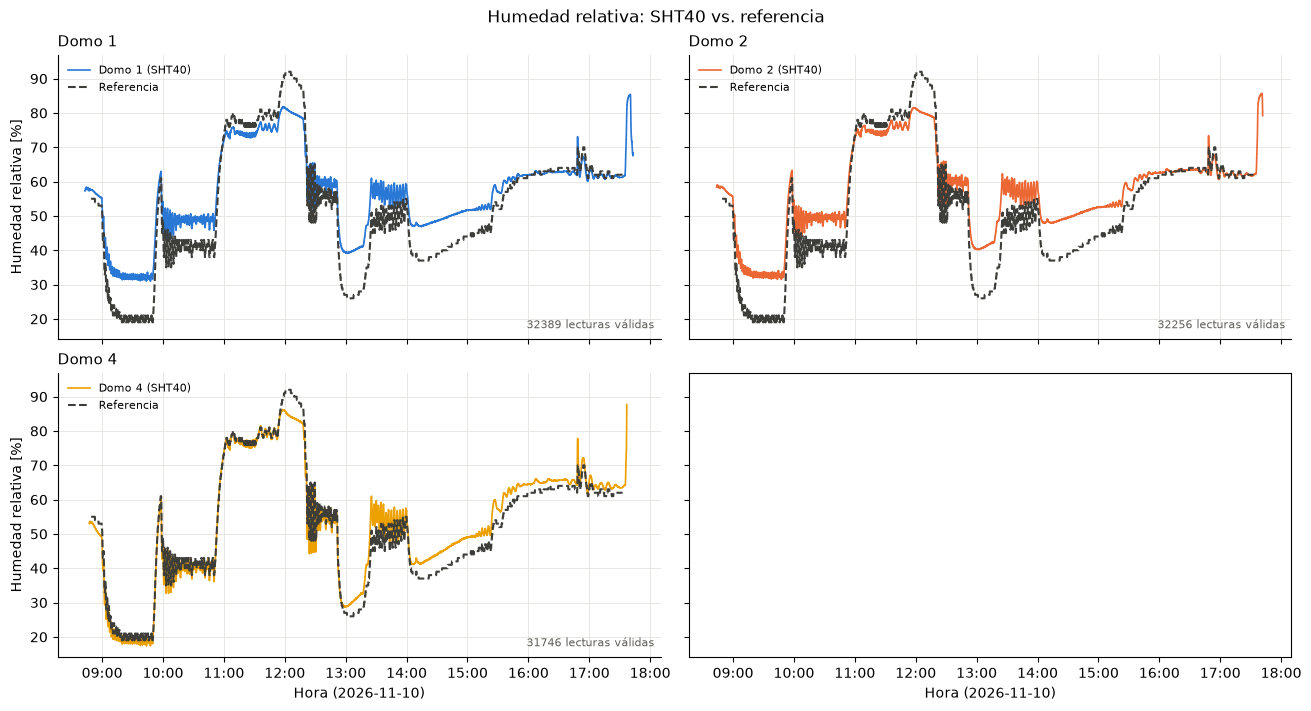

In [6]:
fig_h, _ = graficar_vs_referencia(exp, "SHT_Hum", "RH", "Humedad relativa [%]",
                                  "Humedad relativa: SHT40 vs. referencia", margen=5)
plt.show()

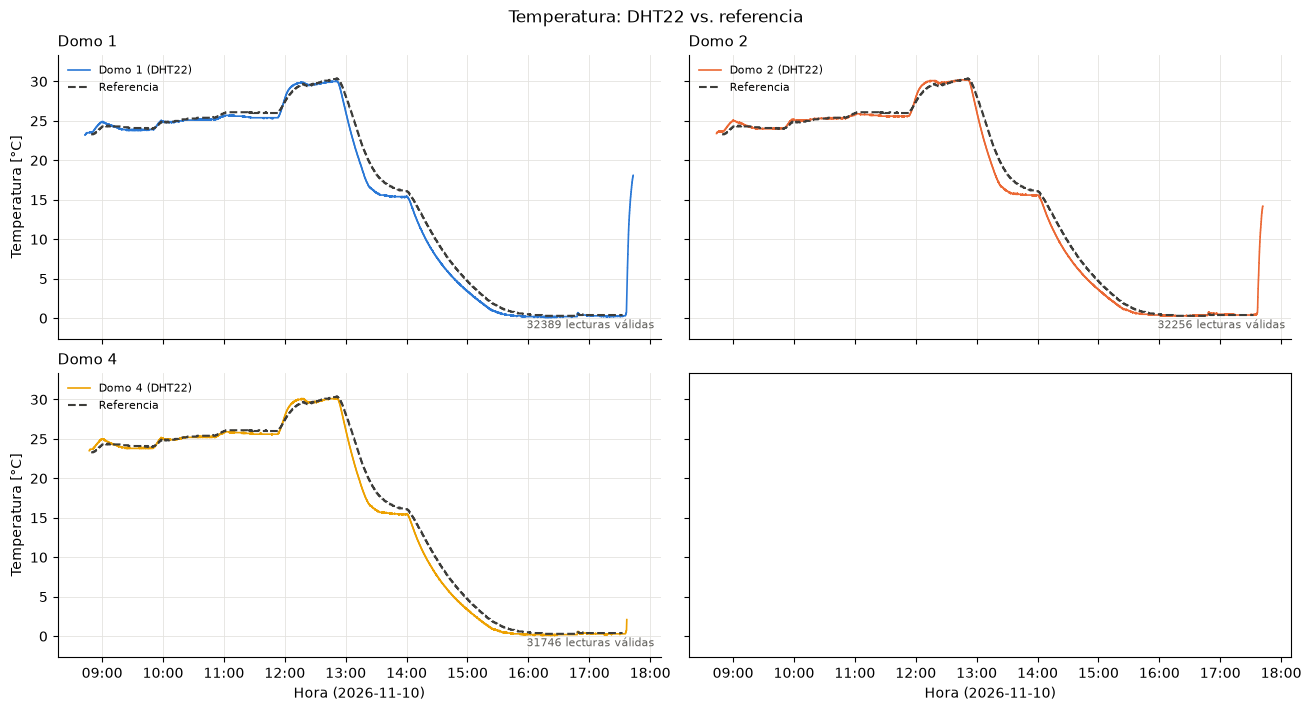

In [7]:
fig_dht_t, _ = graficar_vs_referencia(exp, "DHT_Temp", "AirT_C", "Temperatura [°C]",
                                      "Temperatura: DHT22 vs. referencia",
                                      margen=3, sensor="DHT22")
plt.show()

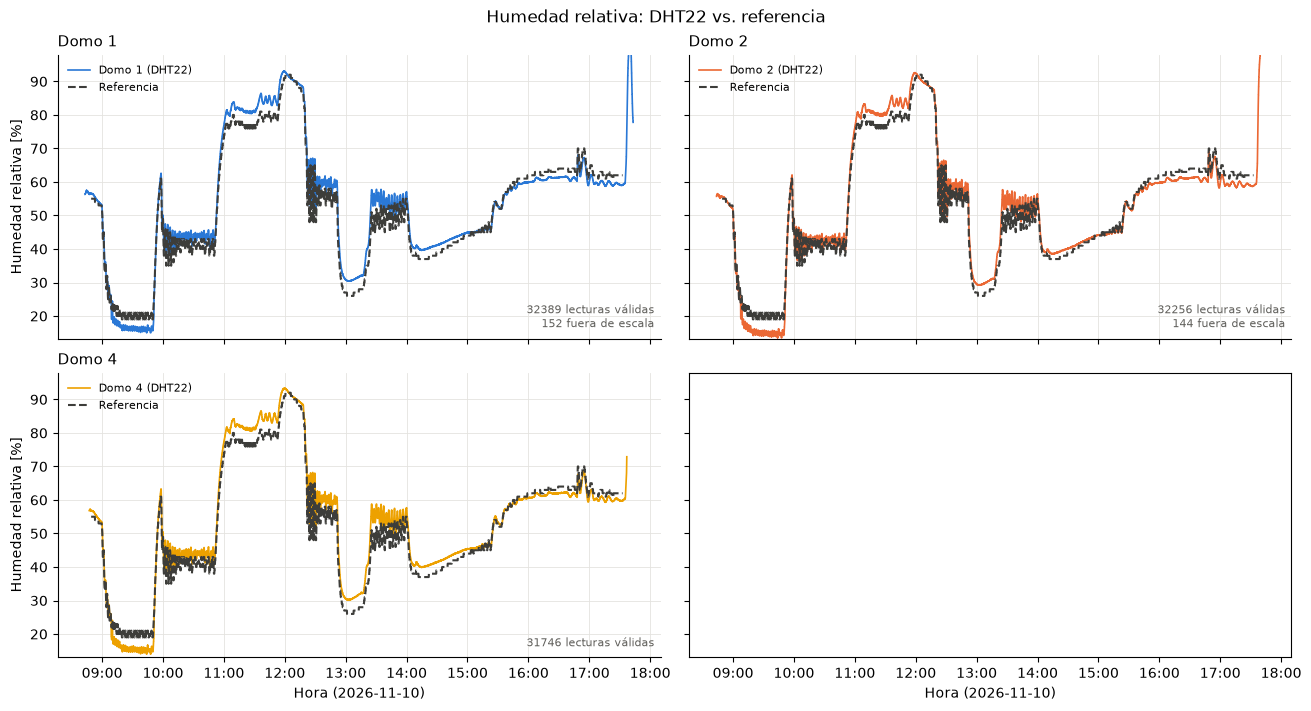

In [8]:
fig_dht_h, _ = graficar_vs_referencia(exp, "DHT_Hum", "RH", "Humedad relativa [%]",
                                      "Humedad relativa: DHT22 vs. referencia",
                                      margen=6, sensor="DHT22")
plt.show()

In [9]:
# ---------------------------------------------------------------------------
# Métricas de error de cada sensor contra la referencia -> `tabla_metricas`
# ---------------------------------------------------------------------------
# Qué columna del domo se compara con qué columna de la referencia.
COMPARACIONES = {
    ("SHT40", "Temperatura [°C]"): ("SHT_Temp", "AirT_C"),
    ("SHT40", "Humedad [%]"): ("SHT_Hum", "RH"),
    ("DHT22", "Temperatura [°C]"): ("DHT_Temp", "AirT_C"),
    ("DHT22", "Humedad [%]"): ("DHT_Hum", "RH"),
}
# La referencia registra cada 10 s y los domos cada 1 s: a cada lectura de la
# referencia se le asigna el promedio de 10 s del domo centrado en esa hora.
VENTANA = "10s"


def emparejar(domo, ref):
    """DataFrame con columnas 'domo' y 'ref' en las horas de la referencia."""
    domo = domo[~domo.index.duplicated()].sort_index()
    domo = domo.rolling(VENTANA, center=True).mean()
    domo = domo.reindex(ref.index, method="nearest", tolerance=pd.Timedelta("1s"))
    return pd.DataFrame({"domo": domo, "ref": ref}).dropna()


pares = {}
filas = []
ref = exp["Referencia"]
for nombre in ESTACIONES:
    for (sensor, variable), (col_domo, col_ref) in COMPARACIONES.items():
        p = emparejar(exp[nombre][col_domo], ref[col_ref])
        pares[(nombre, sensor, variable)] = p
        error = p["domo"] - p["ref"]
        filas.append({
            "estacion": nombre,
            "variable": variable,
            "sensor": sensor,
            "n": len(p),
            "sesgo": error.mean(),  # > 0: el sensor marca más que la referencia
            "r": p["domo"].corr(p["ref"]),
            "MAE": error.abs().mean(),
            "RMSE": np.sqrt((error**2).mean()),
        })

tabla_metricas = pd.DataFrame(filas)
tabla_metricas.round({"sesgo": 2, "r": 4, "MAE": 2, "RMSE": 2})

,estacion,variable,sensor,n,sesgo,r,MAE,RMSE
0,Domo 1,Temperatura [°C],SHT40,3143,-0.88,0.9973,0.94,1.24
1,Domo 1,Humedad [%],SHT40,3143,4.04,0.9926,5.95,7.20
2,Domo 1,Temperatura [°C],DHT22,3143,-0.63,0.9972,0.71,1.06
3,Domo 1,Humedad [%],DHT22,3143,1.11,0.9884,2.66,3.05
4,Domo 2,Temperatura [°C],SHT40,3143,-0.96,0.9965,1.03,1.38
5,Domo 2,Humedad [%],SHT40,3143,4.68,0.9912,6.33,7.71
6,Domo 2,Temperatura [°C],DHT22,3143,-0.45,0.9972,0.61,0.97
7,Domo 2,Humedad [%],DHT22,3143,0.30,0.9900,2.30,2.76
8,Domo 4,Temperatura [°C],SHT40,3143,-1.13,0.9956,1.20,1.59
9,Domo 4,Humedad [%],SHT40,3143,1.20,0.9850,2.65,3.34


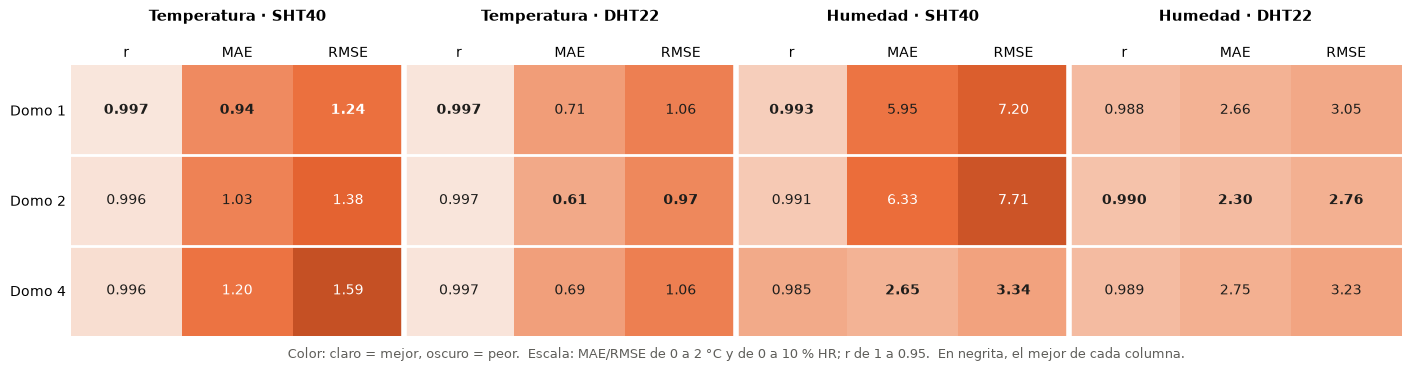

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# ---------------------------------------------------------------------------
# Escala de color: 0 = bueno (claro), 1 = malo (oscuro).
# MAE y RMSE: 0 -> límite de la tabla (sobre el límite queda en el color más oscuro).
# r: 1 -> R_MALO (bajo R_MALO queda en el color más oscuro).
# ---------------------------------------------------------------------------
LIMITE_ERROR = {"Temperatura [°C]": 2.0, "Humedad [%]": 10.0}
R_MALO = 0.95
CMAP_ERROR = LinearSegmentedColormap.from_list("error", ["#fbf3ee", "#f2a27e", "#eb6834", "#8a2c0d"])

VARIABLES = ["Temperatura [°C]", "Humedad [%]"]
SENSORES = ["SHT40", "DHT22"]
METRICAS = ["r", "MAE", "RMSE"]


def nivel_de_error(metrica, variable, valor):
    if metrica == "r":
        return np.clip((1 - valor) / (1 - R_MALO), 0, 1)
    return np.clip(valor / LIMITE_ERROR[variable], 0, 1)


def graficar_grilla(tabla):
    columnas = [(v, s, m) for v in VARIABLES for s in SENSORES for m in METRICAS]
    t = tabla.set_index(["estacion", "variable", "sensor"])

    valores = np.array([[t.loc[(e, v, s), m] for v, s, m in columnas] for e in ESTACIONES])
    niveles = np.array([[nivel_de_error(m, v, t.loc[(e, v, s), m]) for v, s, m in columnas]
                        for e in ESTACIONES])

    fig, ax = plt.subplots(figsize=(14, 3.6), layout="constrained")
    ax.imshow(niveles, cmap=CMAP_ERROR, vmin=0, vmax=1, aspect="auto")

    # Valor en cada celda; se destaca en negrita el mejor de cada columna.
    for j, (v, s, m) in enumerate(columnas):
        col = valores[:, j]
        mejor = np.nanargmax(col) if m == "r" else np.nanargmin(col)
        for i in range(len(ESTACIONES)):
            texto = f"{col[i]:.3f}" if m == "r" else f"{col[i]:.2f}"
            ax.text(j, i, texto, ha="center", va="center", fontsize=10,
                    fontweight="bold" if i == mejor else "normal",
                    color="white" if niveles[i, j] > 0.6 else "#1f1e1c")

    # Ejes y encabezados
    ax.set_yticks(range(len(ESTACIONES)), ESTACIONES)
    ax.set_xticks(range(len(columnas)), [m for _, _, m in columnas])
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for k in range(0, len(columnas), len(METRICAS)):
        v, s, _ = columnas[k]
        ax.text(k + 1, -0.95, f"{v.split(' ')[0]} · {s}", ha="center", va="bottom",
                fontsize=11, fontweight="bold")
        if k:
            ax.axvline(k - 0.5, color="white", lw=4)  # separa los grupos
    for i in range(1, len(ESTACIONES)):
        ax.axhline(i - 0.5, color="white", lw=2)
    ax.spines[:].set_visible(False)

    ax.set_xlabel(
        f"Color: claro = mejor, oscuro = peor.  Escala: MAE/RMSE de 0 a "
        f"{LIMITE_ERROR['Temperatura [°C]']:g} °C y de 0 a {LIMITE_ERROR['Humedad [%]']:g} % HR; "
        f"r de 1 a {R_MALO}.  En negrita, el mejor de cada columna.",
        fontsize=9, color="#5f5e5a", labelpad=8,
    )
    return fig, ax


fig_grilla, _ = graficar_grilla(tabla_metricas)
plt.show()


## Gráficos agrupados por sensor, con los periodos del experimento

In [11]:
# ---------------------------------------------------------------------------
# Periodos del experimento (consignas de la cámara), según el registro manual
# ---------------------------------------------------------------------------
PERIODOS = [
    # (inicio, fin, etiqueta, tipo)
    ("08:50", "09:49", "10 %HR", "humedad"),
    ("09:50", "10:51", "35 %HR", "humedad"),
    ("10:52", "11:51", "80 %HR", "humedad"),
    ("11:52", "12:50", "30 °C", "temperatura"),
    ("12:52", "13:58", "15 °C", "temperatura"),
    ("14:00", "17:33", "0 °C", "temperatura"),
]
PERIODOS = [
    (pd.Timestamp(f"{FECHA} {ini}"), pd.Timestamp(f"{FECHA} {fin}"), etiqueta, tipo)
    for ini, fin, etiqueta, tipo in PERIODOS
]
# Colores distintos a los de las estaciones para no confundir periodos con series.
COLOR_PERIODO = {"humedad": "#7b5cc4", "temperatura": "#8a8478"}


def marcar_periodos(ax):
    """Sombrea cada periodo (morado = consigna de humedad, gris = de temperatura),
    marca sus límites con líneas verticales y escribe la consigna arriba."""
    for k, (ini, fin, etiqueta, tipo) in enumerate(PERIODOS):
        color = COLOR_PERIODO[tipo]
        ax.axvspan(ini, fin, color=color, alpha=0.06 if k % 2 else 0.12, lw=0, zorder=0)
        for borde in (ini, fin):
            ax.axvline(borde, color=color, lw=0.8, ls=":", alpha=0.8, zorder=1)
        ax.text(ini + (fin - ini) / 2, 1.01, etiqueta, transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=9, fontweight="bold", color=color)


def graficar_agrupado(exp, col_domo, col_ref, etiqueta, titulo, sensor):
    """Todas las estaciones (un sensor) y la referencia en un mismo gráfico,
    con los periodos del experimento marcados."""
    fig, ax = plt.subplots(figsize=(14, 5.5), layout="constrained")
    marcar_periodos(ax)

    for nombre in ESTACIONES:
        serie = exp[nombre][col_domo]
        ax.plot(serie.index, serie, lw=1, color=COLORES[nombre], label=f"{nombre} ({sensor})")
    ref = exp["Referencia"][col_ref]
    ax.plot(ref.index, ref, lw=1.8, ls="--", color=COLOR_REF, label="Referencia", zorder=5)

    ax.set_xlim(PERIODOS[0][0] - pd.Timedelta(minutes=10),
                PERIODOS[-1][1] + pd.Timedelta(minutes=10))
    ax.xaxis.set_major_locator(mdates.HourLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_xlabel(f"Hora ({FECHA})")
    ax.set_ylabel(etiqueta)
    ax.grid(True, axis="y", color=COLOR_GRILLA, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1), frameon=False, fontsize=9)
    ax.set_title(titulo, loc="left", fontsize=13, pad=22)
    return fig, ax

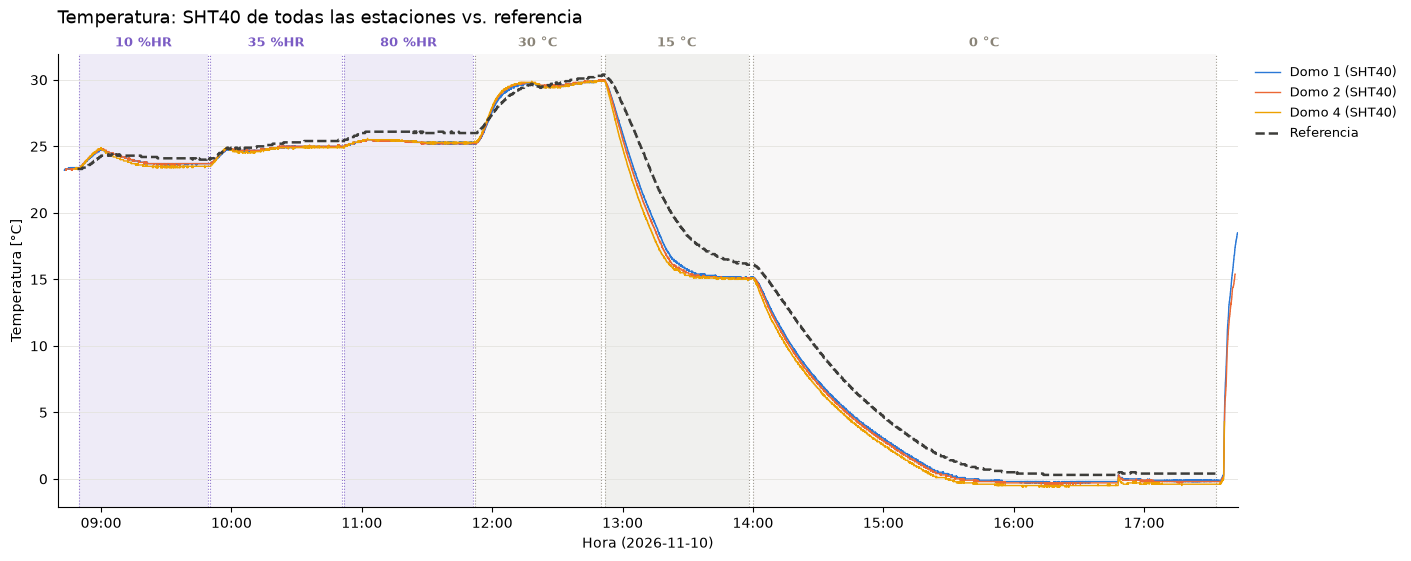

In [12]:
fig_agr_sht_t, _ = graficar_agrupado(exp, "SHT_Temp", "AirT_C", "Temperatura [°C]",
                                      "Temperatura: SHT40 de todas las estaciones vs. referencia", "SHT40")
plt.show()

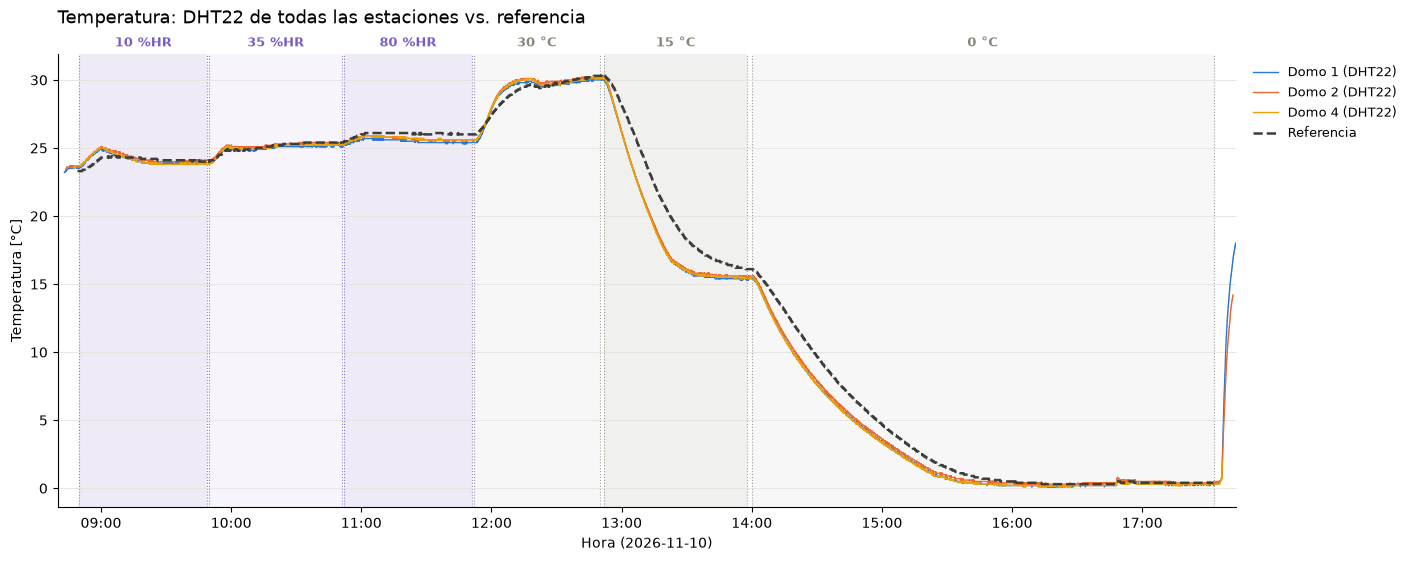

In [13]:
fig_agr_dht_t, _ = graficar_agrupado(exp, "DHT_Temp", "AirT_C", "Temperatura [°C]",
                                      "Temperatura: DHT22 de todas las estaciones vs. referencia", "DHT22")
plt.show()

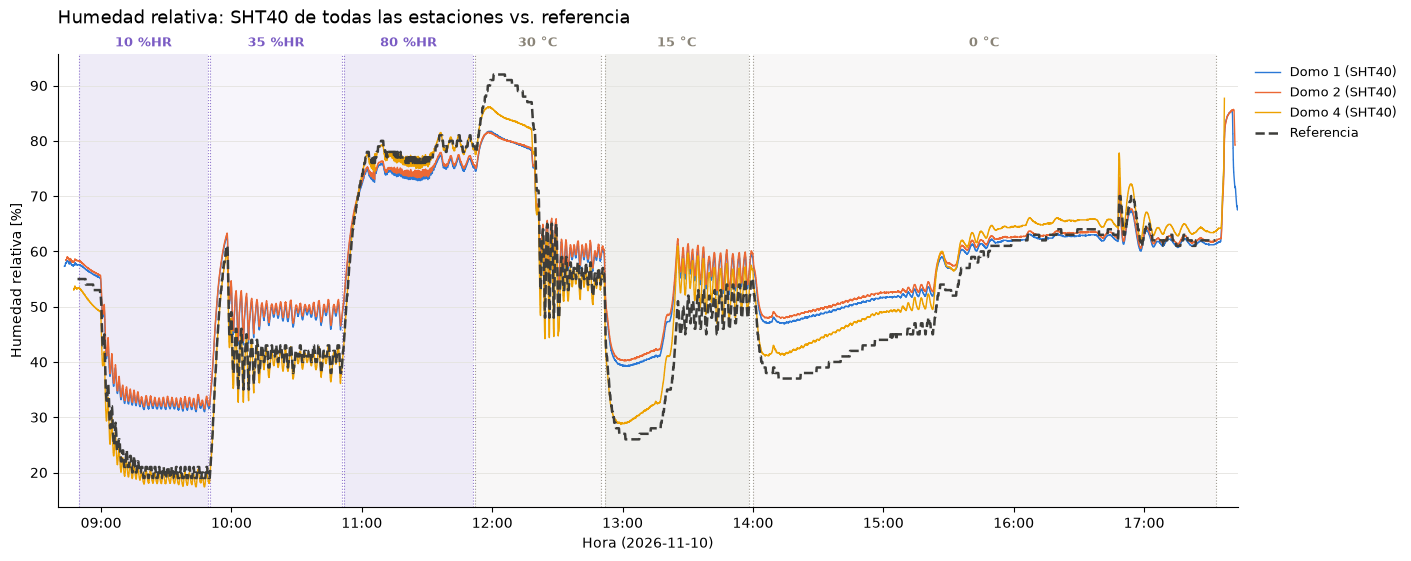

In [14]:
fig_agr_sht_h, _ = graficar_agrupado(exp, "SHT_Hum", "RH", "Humedad relativa [%]",
                                      "Humedad relativa: SHT40 de todas las estaciones vs. referencia", "SHT40")
plt.show()

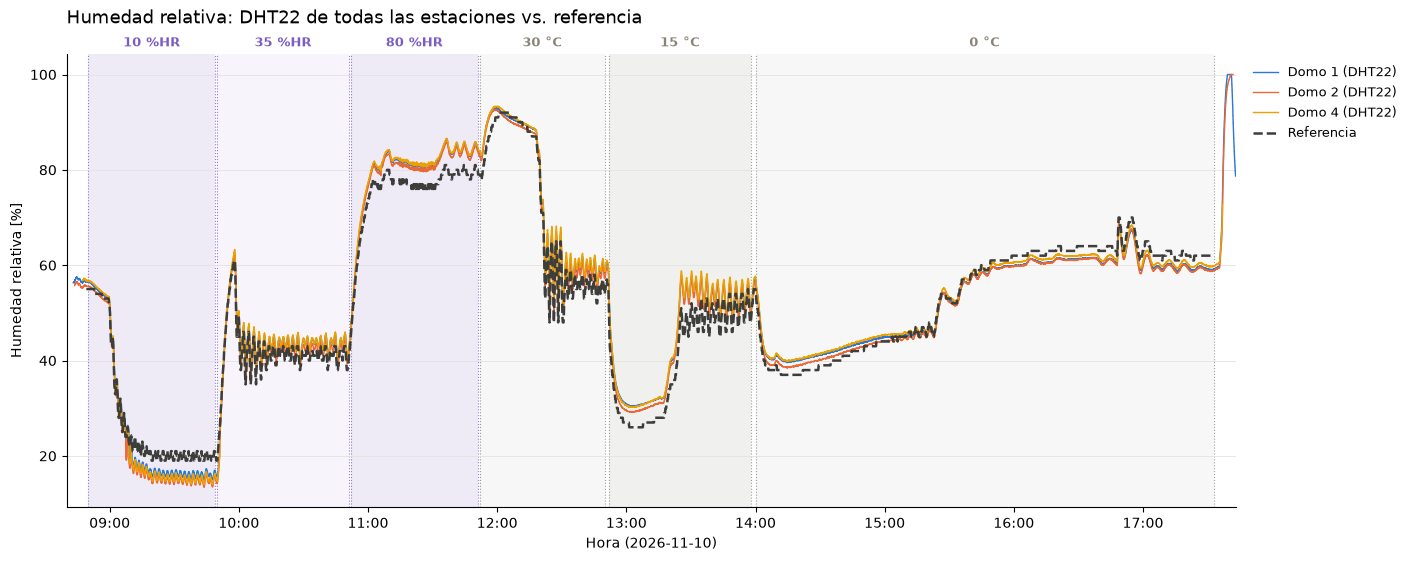

In [15]:
fig_agr_dht_h, _ = graficar_agrupado(exp, "DHT_Hum", "RH", "Humedad relativa [%]",
                                      "Humedad relativa: DHT22 de todas las estaciones vs. referencia", "DHT22")
plt.show()

In [ ]:
# ---------------------------------------------------------------------------
# Calibración lineal de cada sensor contra la referencia
#   valor_corregido = a + b * valor_sensor
# Se ajusta con los últimos 30 min de cada periodo (PERIODOS), donde la cámara
# debería estar estable, usando los pares sensor-referencia cada 10 s.
# ---------------------------------------------------------------------------
VENTANA_CAL = pd.Timedelta(minutes=30)
SENSORES_CAL = {
    # (sensor, variable): (columna del domo, columna de la referencia)
    ("SHT40", "Temperatura [°C]"): ("SHT_Temp", "AirT_C"),
    ("DHT22", "Temperatura [°C]"): ("DHT_Temp", "AirT_C"),
    ("SHT40", "Humedad [%]"): ("SHT_Hum", "RH"),
    ("DHT22", "Humedad [%]"): ("DHT_Hum", "RH"),
}
# Periodos que NO se usan para ajustar (por etiqueta). Ej.: ["15 °C"] si se decide
# que la cámara no alcanzó a estabilizarse en ese tramo.
EXCLUIR_CAL = []
VENTANAS_CAL = [(fin - VENTANA_CAL, fin, etiqueta) for _, fin, etiqueta, _ in PERIODOS
                if etiqueta not in EXCLUIR_CAL]


def rmse(x, y):
    return float(np.sqrt(np.mean((np.asarray(x) - np.asarray(y)) ** 2)))


# Estabilidad de la referencia en cada ventana (una desviación alta = la cámara
# todavía no se estabilizaba y ese tramo es menos confiable para calibrar).
ref = exp["Referencia"]
estabilidad = pd.DataFrame([
    {"periodo": et, "desde": ini.strftime("%H:%M"), "hasta": fin.strftime("%H:%M"),
     "T ref media": ref.loc[ini:fin, "AirT_C"].mean(), "T ref desv": ref.loc[ini:fin, "AirT_C"].std(),
     "HR ref media": ref.loc[ini:fin, "RH"].mean(), "HR ref desv": ref.loc[ini:fin, "RH"].std()}
    for ini, fin, et in VENTANAS_CAL
]).set_index("periodo")
print("Ventanas de calibración (últimos 30 min de cada periodo):")
print(estabilidad.round(2).to_string(), "\n")

# Ajuste por estación, sensor y variable.
filas = []
for nombre in ESTACIONES:
    for (sensor, variable), (col_domo, col_ref) in SENSORES_CAL.items():
        p_total = emparejar(exp[nombre][col_domo], ref[col_ref])  # todo el experimento
        p_cal = pd.concat([p_total.loc[ini:fin] for ini, fin, _ in VENTANAS_CAL])

        b, a = np.polyfit(p_cal["domo"], p_cal["ref"], 1)  # ref ≈ a + b * domo
        cal_corr = a + b * p_cal["domo"]
        total_corr = a + b * p_total["domo"]

        filas.append({
            "estacion": nombre, "sensor": sensor, "variable": variable,
            "a (offset)": a, "b (ganancia)": b,
            "R2": np.corrcoef(p_cal["domo"], p_cal["ref"])[0, 1] ** 2,
            "n": len(p_cal),
            "RMSE ventanas antes": rmse(p_cal["domo"], p_cal["ref"]),
            "RMSE ventanas después": rmse(cal_corr, p_cal["ref"]),
            "RMSE total antes": rmse(p_total["domo"], p_total["ref"]),
            "RMSE total después": rmse(total_corr, p_total["ref"]),
        })

tabla_calibracion = pd.DataFrame(filas)

# Coeficientes listos para usar: CALIBRACION[(estacion, sensor, variable)] = (a, b)
CALIBRACION = {
    (f["estacion"], f["sensor"], f["variable"]): (f["a (offset)"], f["b (ganancia)"])
    for f in filas
}

# Datos corregidos: copia de `exp` con columnas nuevas *_cal (las originales no se tocan).
exp_cal = {"Referencia": exp["Referencia"]}
for nombre in ESTACIONES:
    df = exp[nombre].copy()
    for (sensor, variable), (col_domo, _) in SENSORES_CAL.items():
        a, b = CALIBRACION[(nombre, sensor, variable)]
        df[f"{col_domo}_cal"] = a + b * df[col_domo]
    exp_cal[nombre] = df

for variable in ["Temperatura [°C]", "Humedad [%]"]:
    print(f"Calibración {variable}   (corregido = a + b · sensor)")
    print(tabla_calibracion[tabla_calibracion["variable"] == variable]
          .drop(columns="variable").round({"a (offset)": 3, "b (ganancia)": 4, "R2": 4,
                                           "RMSE ventanas antes": 2, "RMSE ventanas después": 2,
                                           "RMSE total antes": 2, "RMSE total después": 2})
          .to_string(index=False), "\n")